# Pipeline huấn luyện ViT: mỗi lần chạy train tiếp và nối kết quả

Mỗi lần **Run All**:

1. Sao lưu run hiện tại vào `runs/backups/` (giữ `KEEP_BACKUPS` bản gần nhất).
2. Nạp **đúng** model đang lưu trong `runs/<RUN>.pt` và train thêm `STEPS` bước.
3. **Nối** log và danh sách ván của lần này vào sau run cũ (`save_run(append=True)`): bước env tiếp nối, các cột tích lũy (ma, viên năng lượng, số lần chết) cộng tiếp. Không train lại từ đầu, không vẽ lại từ đầu.
4. Ghi một dòng vào `runs/<RUN>_sessions.json` (lần chạy này bắt đầu / kết thúc ở bước nào, điểm trước và sau) và chấm điểm 20 ván vào `runs/<RUN>_eval_history.json`.
5. Vẽ toàn bộ lịch sử huấn luyện (các giai đoạn trước, rồi từng lần chạy nối tiếp) và bảng các lần chạy.

Điều cần biết:
- **Model được ghi đè** bằng bản mới nhất sau mỗi lần chạy; bản trước nằm trong `runs/backups/`.
- Nếu bạn **ngắt** (Interrupt) giữa chừng, `train_ppo` trả về phần đã train dở và notebook **vẫn lưu phần đó** (nếu có ít nhất 20 ván). Nếu kernel **chết** hẳn, run chính không đổi, mất tối đa lần chạy đang dở (checkpoint giữa chừng nằm ở `runs/ckpt/`, chỉ có trọng số).
- **Chốt chặn sụp:** nếu điểm trung bình 100 ván cuối của lần chạy này thấp hơn `COLLAPSE_RATIO` x điểm trước đó thì **không lưu**, để khỏi ghi đè model tốt bằng model hỏng (đã từng xảy ra với run RGB, mục 8 báo cáo).
- Mỗi lần `train_ppo` dùng lịch lr giảm tuyến tính về 0 trong lần đó, nên lr dạng răng cưa giữa các lần chạy.
- Điểm train là điểm các ván hoàn thành lúc policy còn đổi; điểm chấm lại (20 ván, seed 1000) **rất nhiễu** (cùng model từng lệch 100–250 điểm giữa các lần chấm), đừng diễn giải chênh lệch nhỏ.

## 0. Cấu hình

In [1]:
import json, time, shutil
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pacman_rl import PPOConfig, train_ppo, get_device
from pacman_rl.runs import save_run, load_run
from pacman_rl.evaluation import ppo_policy, evaluate

RUN_DIR = Path("runs")                         # chạy notebook từ thư mục notebooks/
RUN = "vit_dp2_sp0.05_plus5M_from_A_s0"        # run ViT được train tiếp. Tên cố định: mỗi lần chạy NỐI vào run này
HISTORY = ["vit_dp25_s0", "vit_dp25_sp0.05_from_pre_s0", "vit_dp25_sp0.05_ext5M_s0"]   # các giai đoạn trước RUN, chỉ để vẽ

STEPS = 500_000          # số bước train thêm mỗi lần chạy (ViT ~300-600 bước/giây: 1M ~ 30-55 phút)
LR = 5e-5                  # như các giai đoạn train tiếp trước (ViT). Adam tạo mới mỗi lần chạy
DP, SP = 5, 0.5         # death_penalty, step_penalty: giữ như giai đoạn cuối của run này
SEED_BASE = 100            # seed lần chạy thứ k = SEED_BASE + k, để các lần chạy không lặp lại cùng chuỗi seed
TRAIN = True               # False: chỉ vẽ lại lịch sử, không train
EVAL_AFTER = True          # chấm 20 ván sau mỗi lần chạy (~4 phút)
N_EVAL = 20
COLLAPSE_RATIO = 0       # không lưu nếu điểm TB 100 ván cuối < ngưỡng này x điểm trước đó
KEEP_BACKUPS = 5

FILES = [RUN_DIR / f"{RUN}.pt", RUN_DIR / f"{RUN}_log.npy", RUN_DIR / f"{RUN}_episodes.npy"]
SESSIONS = RUN_DIR / f"{RUN}_sessions.json"
EVALS = RUN_DIR / f"{RUN}_eval_history.json"
CKPT = RUN_DIR / "ckpt" / f"{RUN}.pt"          # checkpoint giữa chừng, tách khỏi run chính

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
device = get_device()
print(device, "|", RUN)

cuda | vit_dp2_sp0.05_plus5M_from_A_s0


## 1. Hàm phụ và trạng thái hiện tại của run

In [2]:
def read_json(p, default):
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else default

def write_json(p, obj):
    p.write_text(json.dumps(obj, ensure_ascii=False, indent=1), encoding="utf-8")

def load_stage(name):
    ep = np.load(RUN_DIR / f"{name}_episodes.npy").astype(float)           # cột 0: bước env, cột 1: điểm thật của ván
    log = np.load(RUN_DIR / f"{name}_log.npy", allow_pickle=True).item()
    return ep, {k: np.asarray(v, dtype=float) for k, v in log.items()}

def run_total_steps():
    """Tổng bước hiện có của RUN (cùng cách save_run tính offset khi nối)."""
    ep, log = load_stage(RUN)
    return float(max(log["step"][-1], ep[-1, 0] if len(ep) else 0))

missing = [f for f in FILES if not f.exists()]
assert not missing, f"thiếu file của run {RUN}: {missing}"
sessions = read_json(SESSIONS, [])
evals = read_json(EVALS, [])
ep0, _ = load_stage(RUN)
print(f"hiện có: {run_total_steps() / 1e6:.2f}M bước, {len(ep0)} ván, điểm TB 100 ván cuối {ep0[-100:, 1].mean():.0f}, "
      f"{len(sessions)} lần chạy đã ghi nhận")

hiện có: 8.65M bước, 12774 ván, điểm TB 100 ván cuối 532, 8 lần chạy đã ghi nhận


## 2. Train tiếp và nối kết quả

Cell này sao lưu, nạp đúng model hiện có, train `STEPS` bước, kiểm tra chốt chặn, rồi nối vào run. Đặt `TRAIN = False` ở mục 0 nếu chỉ muốn xem lại biểu đồ.

In [13]:
if TRAIN:
    # 1. sao lưu run hiện tại (model + log + episodes + sessions + eval)
    bdir = RUN_DIR / "backups" / f"{RUN}_{datetime.now():%Y%m%d_%H%M%S}"
    bdir.mkdir(parents=True)
    for f in FILES + [SESSIONS, EVALS]:
        if f.exists():
            shutil.copy2(f, bdir / f.name)
    old = sorted((RUN_DIR / "backups").glob(f"{RUN}_*"))
    for d in old[:-KEEP_BACKUPS]:                              # chỉ xóa bản sao lưu cũ của chính run này
        shutil.rmtree(d)
    print("đã sao lưu ->", bdir)

    # 2. mốc trước khi train
    start_step = run_total_steps()
    ep_before, _ = load_stage(RUN)
    score_before = float(ep_before[-100:, 1].mean())

    # 3. nạp ĐÚNG model hiện có rồi train tiếp
    model = load_run(RUN_DIR, RUN, "ppo", device).model.train()
    k = len(sessions)
    cfg = PPOConfig(arch="vit", lr=LR, total_steps=STEPS, seed=SEED_BASE + k,
                    death_penalty=DP, step_penalty=SP, rgb_scale=False,
                    n_envs=32, n_steps=512, n_minibatches=4, save_every=10, log_every=10)
    t0 = time.time()
    result = train_ppo(cfg=cfg, model=model, save_path=str(CKPT), device=device)
    hours = (time.time() - t0) / 3600

    # 4. chốt chặn rồi nối vào run
    eps = np.asarray(result[2], dtype=float).reshape(-1, 2)
    n_new = len(eps)
    score_after = float(eps[-100:, 1].mean()) if n_new else float("nan")
    print(f"lần chạy {k + 1}: {n_new} ván, điểm TB {min(100, n_new)} ván cuối {score_after:.0f} (trước đó {score_before:.0f}), {hours:.2f}h")
    if n_new < 20:
        print("!!! quá ít ván (<20), không lưu. Run chính giữ nguyên.")
    elif score_after < COLLAPSE_RATIO * score_before:
        print(f"!!! điểm {score_after:.0f} < {COLLAPSE_RATIO} x {score_before:.0f}: nghi sụp, KHÔNG lưu. "
              f"Run chính giữ nguyên (bản sao lưu: {bdir}). Kiểm tra lr / penalty trước khi chạy lại.")
    else:
        save_run(result, RUN_DIR, RUN, append=True)
        end_step = run_total_steps()
        sessions.append({"lần": k + 1, "thời điểm": f"{datetime.now():%Y-%m-%d %H:%M}",
                         "bước bắt đầu": start_step, "bước kết thúc": end_step, "số ván mới": n_new,
                         "điểm TB trước": score_before, "điểm TB sau": score_after,
                         "lr": LR, "death_penalty": DP, "step_penalty": SP, "seed": SEED_BASE + k, "giờ": round(hours, 3)})
        write_json(SESSIONS, sessions)
        print(f"đã nối vào {RUN}: {start_step / 1e6:.2f}M -> {end_step / 1e6:.2f}M bước")

        # 5. chấm điểm lại (tùy chọn)
        if EVAL_AFTER:
            m = load_run(RUN_DIR, RUN, "ppo", device).model.to(device).eval()
            sc = np.asarray(evaluate(ppo_policy(m, device), n_episodes=N_EVAL, seed=1000))
            evals.append({"lần": k + 1, "tổng bước": end_step, "n": N_EVAL, "TB": float(sc.mean()),
                          "std": float(sc.std()), "trung vị": float(np.median(sc)), "max": float(sc.max())})
            write_json(EVALS, evals)
            print(f"chấm {N_EVAL} ván: TB {sc.mean():.0f} | std {sc.std():.0f} | trung vị {np.median(sc):.0f} | max {sc.max():.0f}")
else:
    print("TRAIN = False: bỏ qua huấn luyện")

đã sao lưu -> runs\backups\vit_dp2_sp0.05_plus5M_from_A_s0_20261111_212505
PPO: 30 updates x 16384 mẫu = 491,520 bước, 32 env song song
Update 10/30 | step 163,840 | avg score(20) 481 | 870 lượt | 188 bước/lượt | 0.21 viên NL/lượt | 0.11 ma/lượt | phạt chết 5.0 bước 0.500 | entropy 2.088 | KL -0.0005 | clipfrac 0.000 | 238 steps/s
Update 20/30 | step 327,680 | avg score(20) 514 | 852 lượt | 192 bước/lượt | 0.20 viên NL/lượt | 0.13 ma/lượt | phạt chết 5.0 bước 0.500 | entropy 2.087 | KL 0.0002 | clipfrac 0.000 | 252 steps/s
Update 30/30 | step 491,520 | avg score(20) 430 | 858 lượt | 191 bước/lượt | 0.22 viên NL/lượt | 0.16 ma/lượt | phạt chết 5.0 bước 0.500 | entropy 2.084 | KL 0.0000 | clipfrac 0.000 | 259 steps/s
lần chạy 8: 851 ván, điểm TB 100 ván cuối 532 (trước đó 522), 0.53h
đã nối vào vit_dp2_sp0.05_plus5M_from_A_s0: 8.16M -> 8.65M bước
chấm 20 ván: TB 466 | std 363 | trung vị 385 | max 1810


## 3. Toàn bộ lịch sử huấn luyện

Trục x = tổng bước env của cả chuỗi ViT (các giai đoạn trước + mọi lần chạy nối tiếp). Đường chấm đứng = đầu mỗi lần chạy; hình thoi = điểm chấm lại 20 ván (thanh sai số = sai số chuẩn).

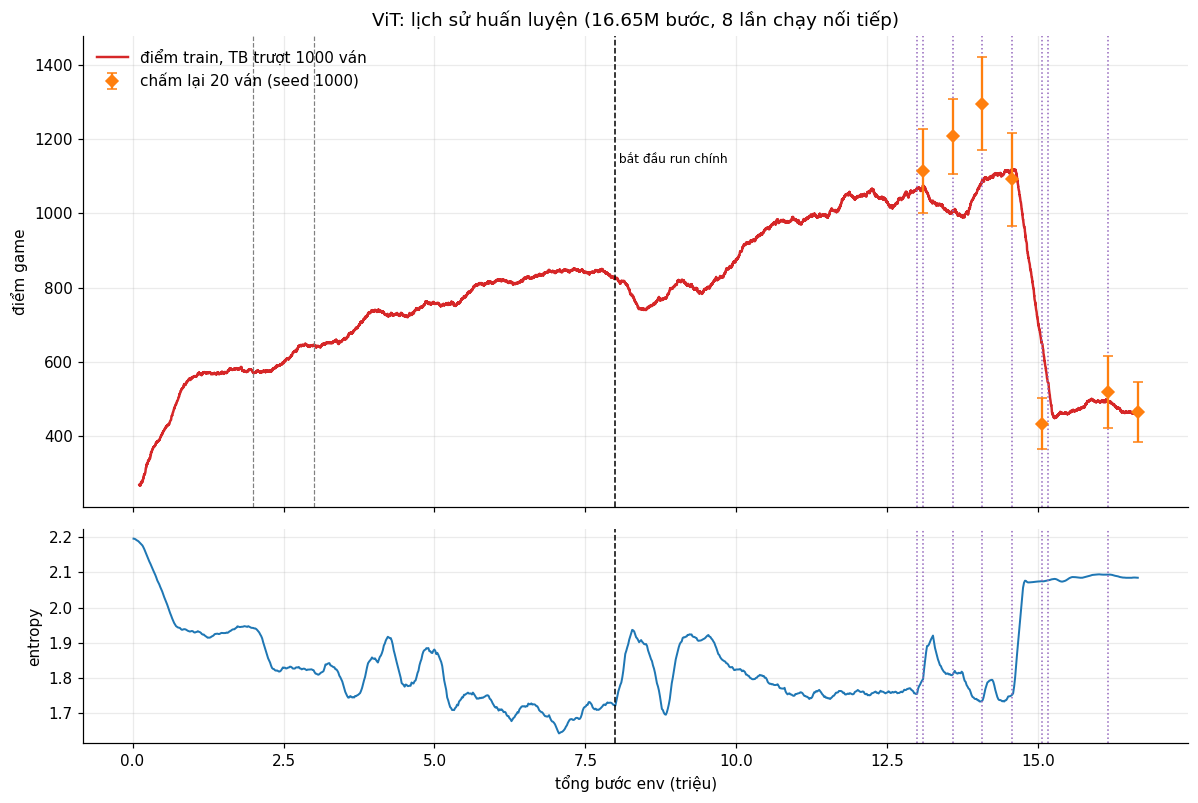

In [14]:
SMOOTH = 1000
sessions = read_json(SESSIONS, [])
evals = read_json(EVALS, [])

# nối các giai đoạn trước (chỉ để vẽ) rồi tới RUN (đã gồm mọi lần chạy nối tiếp)
off, eps_all, ent_x, ent_y = 0.0, [], [], []
bounds = []
for n in HISTORY + [RUN]:
    ep, log = load_stage(n)
    eps_all.append(np.c_[ep[:, 0] + off, ep[:, 1]])
    ent_x.append(log["step"] + off); ent_y.append(log["ent"])
    bounds.append(off)
    off += max(log["step"][-1], ep[-1, 0])
ep_all = np.vstack(eps_all)
run_off = bounds[-1]                                   # nơi RUN bắt đầu trong trục x chung
ent_x, ent_y = np.concatenate(ent_x), np.concatenate(ent_y)

fig, axes = plt.subplots(2, 1, figsize=(11, 7.4), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
sm = pd.Series(ep_all[:, 1]).rolling(SMOOTH, min_periods=SMOOTH // 5).mean().to_numpy()
ax.plot(ep_all[:, 0] / 1e6, sm, color="tab:red", lw=1.6, label=f"điểm train, TB trượt {SMOOTH} ván")
for b in bounds[1:-1]:
    ax.axvline(b / 1e6, color="gray", ls="--", lw=0.8)
ax.axvline(run_off / 1e6, color="k", ls="--", lw=1)
ax.text(run_off / 1e6, ax.get_ylim()[1], " bắt đầu run chính", va="top", fontsize=8)
for s in sessions:
    ax.axvline((run_off + s["bước bắt đầu"]) / 1e6, color="tab:purple", ls=":", lw=1)
if evals:
    xe = [(run_off + e["tổng bước"]) / 1e6 for e in evals]
    ax.errorbar(xe, [e["TB"] for e in evals], yerr=[e["std"] / np.sqrt(e["n"]) for e in evals],
                fmt="D", color="tab:orange", capsize=3, label=f"chấm lại {N_EVAL} ván (seed 1000)")
ax.set_ylabel("điểm game"); ax.set_title(f"ViT: lịch sử huấn luyện ({off / 1e6:.2f}M bước, {len(sessions)} lần chạy nối tiếp)")
ax.legend(loc="upper left", frameon=False)

ax = axes[1]
ax.plot(ent_x / 1e6, pd.Series(ent_y).rolling(10, min_periods=1).mean(), color="tab:blue", lw=1.3)
ax.axvline(run_off / 1e6, color="k", ls="--", lw=1)
for s in sessions:
    ax.axvline((run_off + s["bước bắt đầu"]) / 1e6, color="tab:purple", ls=":", lw=1)
ax.set_ylabel("entropy"); ax.set_xlabel("tổng bước env (triệu)")
fig.tight_layout()
fig.savefig(RUN_DIR / f"{RUN}_history.png", dpi=150)
plt.show()

## 4. Bảng các lần chạy nối tiếp và điểm chấm lại

In [15]:
if sessions:
    df = pd.DataFrame(sessions)
    df["bước bắt đầu"] = df["bước bắt đầu"] / 1e6
    df["bước kết thúc"] = df["bước kết thúc"] / 1e6
    df = df.rename(columns={"bước bắt đầu": "từ (M bước)", "bước kết thúc": "đến (M bước)"})
    if evals:
        ev = pd.DataFrame(evals).set_index("lần")[["TB", "std", "trung vị", "max"]].add_prefix("chấm lại ")
        df = df.set_index("lần").join(ev).reset_index()
    display(df.round(2))
else:
    print("chưa có lần chạy nối tiếp nào được ghi nhận (chạy mục 2 trước).")

,lần,thời điểm,từ (M bước),đến (M bước),số ván mới,điểm TB trước,điểm TB sau,lr,death_penalty,step_penalty,seed,giờ,chấm lại TB,chấm lại std,chấm lại trung vị,chấm lại max
0,1,2026-11-09 11:37,5.00,5.10,123,1180.6,977.3,0.0,2.5,0.05,100,0.04,1115.0,506.66,1060.0,2340.0
1,2,2026-11-09 13:48,5.10,5.59,670,977.3,1076.4,0.0,2.5,0.05,101,0.32,1208.0,454.35,1165.0,2150.0
2,3,2026-11-09 15:43,5.59,6.08,632,1076.4,1183.8,0.0,2.5,0.05,102,1.77,1296.0,559.57,1175.0,2370.0
3,4,2026-11-09 19:28,6.08,6.57,641,1183.8,1141.2,0.0,2.5,0.05,103,0.41,1092.0,563.27,905.0,2470.0
4,5,2026-11-09 21:51,6.57,7.06,798,1141.2,493.5,0.0,5.0,0.30,104,0.34,434.0,306.60,350.0,1210.0
5,6,2026-11-09 22:18,7.06,7.16,155,493.5,431.1,0.0,5.0,1.00,105,0.39,NaN,NaN,NaN,NaN
6,7,2026-11-11 17:54,7.16,8.16,1708,431.1,522.1,0.0,5.0,1.00,106,1.35,519.5,434.65,395.0,2050.0
7,8,2026-11-11 21:56,8.16,8.65,851,522.1,532.0,0.0,5.0,0.50,107,0.53,465.5,363.23,385.0,1810.0


## 5. Xem agent chơi

Nạp lại model **mới nhất đã lưu** của `RUN` (không dùng biến `model` đang train dở). Cần màn hình và OpenCV; phím `q` để thoát cửa sổ. Điểm mỗi ván dao động rất mạnh, đừng đánh giá qua một ván.

In [3]:
WATCH_GREEDY = False    # False = lấy mẫu từ policy (thường tốt hơn greedy với model này)
WATCH_SEED = None       # số nguyên để lặp lại ván, None = ngẫu nhiên

play_model = load_run(RUN_DIR, RUN, "ppo", device).model.to(device).eval()
print("đã nạp", RUN, f"({run_total_steps() / 1e6:.2f}M bước)")

đã nạp vit_dp2_sp0.05_plus5M_from_A_s0 (8.65M bước)


### 5a. Cửa sổ có bảng xác suất 9 hành động

In [4]:
from pacman_rl import watch_probs
watch_probs(play_model, device, greedy=WATCH_GREEDY, eps=0.0, scale=3, delay_ms=30, seed=WATCH_SEED)

c:\Users\LENOVO\miniconda3\envs\rel_pacman\lib\site-packages\torch\nn\modules\transformer.py:720: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:455.)
  return torch._transformer_encoder_layer_fwd(


[watch_probs] 590 điểm (734 bước)


590.0

### 5b. Xem bình thường (cửa sổ ALE gốc, in điểm từng ván)

In [5]:
from pacman_rl.evaluation import ppo_policy, watch
watch(ppo_policy(play_model, device, greedy=WATCH_GREEDY), episodes=1)

[play] ván 1: 350 điểm (453 bước)


[350.0]

### 5c. Tự chơi (người chơi)

Cửa sổ OpenCV mở ngoài notebook, click vào cửa sổ để nhận phím. `WASD` hoặc phím mũi tên để đổi hướng (Pacman tự đi tiếp theo hướng vừa bấm), `q` để thoát. Game chạy cùng tốc độ với lúc agent chơi (bỏ qua 4 frame mỗi bước), một ván đủ 3 mạng.

In [11]:
import cv2
import gymnasium as gym
import ale_py

gym.register_envs(ale_py) if hasattr(gym, "register_envs") else None

# phím -> action (waitKeyEx trả mã mở rộng cho phím mũi tên trên Windows)
KEYMAP = {ord("w"): "UP", ord("s"): "DOWN", ord("a"): "LEFT", ord("d"): "RIGHT",
          2490368: "UP", 2621440: "DOWN", 2424832: "LEFT", 2555904: "RIGHT"}


def play_human(scale=3, delay_ms=66, seed=None):
    """Tự chơi bằng WASD hoặc phím mũi tên. Pacman tự đi tiếp theo hướng vừa bấm. Phím q để thoát."""
    env = gym.make("ALE/MsPacman-v5", frameskip=4, repeat_action_probability=0.0, render_mode="rgb_array")
    ids = {n: i for i, n in enumerate(env.unwrapped.get_action_meanings())}
    env.reset(seed=seed)
    action, score, scores = ids["NOOP"], 0.0, []
    try:
        while True:
            frame = cv2.resize(env.render()[:, :, ::-1], None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
            cv2.putText(frame, f"score {score:.0f}", (5, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 1)
            cv2.imshow("Ms. Pacman - ban choi", frame)
            key = cv2.waitKeyEx(delay_ms)
            if key == ord("q"):
                break
            if key in KEYMAP:
                action = ids[KEYMAP[key]]
            _, r, te, tr, _ = env.step(action)
            score += r
            if te or tr:
                scores.append(score); print(f"Ván {len(scores)}: {score:.0f} điểm")
                break
    finally:
        env.close(); cv2.destroyAllWindows(); cv2.waitKey(1)
    return scores or [score]


human_scores = play_human()
print("Điểm:", human_scores)

Ván 1: 4660 điểm
Điểm: [4660.0]
